In [1]:
import os
import pickle
import dill
import pprint
import itertools
import pathos
import pprint
import functools
from functools import partial
from pathlib import Path
import logging
import json

import pandas as pd
import numpy as np
from scipy import stats as st
from sklearn.feature_selection import mutual_info_regression as MI
from statsmodels.stats.multitest import multipletests

import json
import plotly.graph_objects as go
from matplotlib import pyplot as plt
import seaborn as sns
sns.set()

import sys
sys.path.append('/Users/leonardo.tessarolo/git/bayesian_bss/')
from src import VisualizationUtilities, DiscreteExperimentParser, AnalysisUtilities, HypothesisTestsCases

/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:1546: SyntaxWarning: invalid escape sequence '\h'
  '$\hat{k}$',
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:2735: SyntaxWarning: invalid escape sequence '\h'
  ['$\hat{k}$', 'u', '$\sigma$']
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:2735: SyntaxWarning: invalid escape sequence '\s'
  ['$\hat{k}$', 'u', '$\sigma$']
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:3361: SyntaxWarning: invalid escape sequence '\h'
  label='$\hat{b}_{11}$'
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:3418: SyntaxWarning: invalid escape sequence '\h'
  label='$\hat{b}_{12}$'
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:3473: SyntaxWarning: invalid escape sequence '\h'
  label='$\hat{b}_{21}$'
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:3528: SyntaxWarning: invalid escape sequence '\h'
  label='$\hat{b}_{22}$'
/Users/leonard

# ANÁLISE: EXPERIMENTO DISCRETO

Heurísticas de análise:
 - 12 casos de teste, com variação de $r_{s}$ (3 especificações) e $p_{\bf{B}}(\bf{B})$ (4 especificações).
 - Geração de 150 realizações, com avaliação de convergência MCMC ($\hat{R}$) e Gradiente Ascendente (ganho iterativo na função-objetivo abaixo de limiar pré-especificado).
 - Para uma realização ser considerada, deve convergir em ambos MCMC e Gradiente Ascendente, considerando todos os 12 casos de teste.

Análises:
 - Gráficos de pontos de máximo em grid bi-dimensional (u,v).
 - Dispersões das taxas de erro de recuperação das fontes $\delta_{\bf{S}}({\bf{S}})$ e de identificação da matriz separadora $\delta_{\bf{B}}({\bf{B}})$, por realização e caso de teste. Estimativas MAP/MMSE são consideradas, além das matrizes correspondentes aos pontos de máximo (u,v).
 - Gráficos de traço dos coeficientes nos algoritmos MCMC e GA.
 - Evolução da log-posteriori no GA.
 - Propriedades das posterioris, por coeficiente de $\bf{B}$, com base em amostras MCMC: média, variância, assimetria e curtose.

Resultados:
 - 121/150 ($\approx 80.7 \%$) das realizações atendem critérios de convergência.
 - MMSE mantém padrão de erros da quali;
 - Gráficos de varreduras (u,v) idênticos aos do artigo CBA. Padrão de rejeição ou não rejeição de hipótese nula em comparações estatísticas idêntico ao do artigo.
 - Após aumento da rigorosidade na convergência do GA, moda a posteriori apresenta padrão de erros entre casos de teste semelhante ao da média a posteriori.
 - Tanto no MAP quanto no MMSE, e tanto para $\delta_{\bf{S}}({\bf{S}})$ quanto para $\delta_{\bf{B}}({\bf{B}})$, para casos com mesma $r_{s}$, hipótese nula de ausencia de diferença não é rejeitada entre pares i-ii e v-vi. Para MMSE, também não é rejeitado par ix-x.
 - Tanto no MAP quanto no MMSE, e tanto para $\delta_{\bf{S}}({\bf{S}})$ quanto para $\delta_{\bf{B}}({\bf{B}})$ para casos de teste de mesma priori, hipótese nula de ausencia de diferença não é rejeitada entre pares iv-viii.
 - Análise estatística MAP vs MMSE: rejeição de hipotese nula em todos os casos, exceto para casos iii e vii (priori correta e informativa). Diferença entre médias, porém, é da ordem de 1-5% dos valores das médias.
 - Erros de recuperação das fontes considerando pontos de máximo (u,v) são menores que MAP/MMSE: varredura não permite afastamento da diagonal principal de $\underline{\bf{B}}$.
 - Considerando MAP/MMSE, caso xii teve maiores erros de recuperação que o xi, contrariando resultado CBA: descasamento de modelo das fontes leva a identificação de matrizes aproximadamente diagonais por MAP/MMSE, que não são acessíveis pela varredura da grade (u,v).
 - Tendência de aumento da variância das amostras MCMC em casos mal-especificados, seja na verossimilhança ou na priori.
 - Assimetrias e curtoses mais dispersas entre realizações, para coeficientes fora da diagonal principal, para casos iv e viii.

Próximos passos:
 - Explicações sobre propriedades das posterioris observadas.
 - Aprofundamento sobre porque fontes triangulares com verossimilhança logistica leva à identificação de matrizes quase diagonais.
 - Justificativa sobre caso xii ter tido menores erros que casos ix/x.
 - Ajuste de reprodutibilidade.
 - Execução de experimento via script.
 - (Se der) geração de HTML com análises do experimento.
 - Subida no GitHub;


# 1. Read and parse raw results

In [2]:
# Experiment name
EXPERIMENT_NAME = 'CBA_SBRT_complete_analysis'

# Whether or not to save graphs
SAVE_GRAPHS=True

# Whether or not to create folder structure for saving results
CREATE_FOLDER_STRUCTURE = True

# Folder which will contain output directory tree
OUTPUT_DIR='./output'
base_output_path=Path(OUTPUT_DIR)

# Directory which holds experiments
experiment_dir = base_output_path / EXPERIMENT_NAME

# Instantiate and execute parser object
parser = DiscreteExperimentParser(experiment_dir)
parser.parse(verbose=True)


####################################################################################################
Total of 150 realizations with executed results
----------------------------------------------------------------------------------------------------
Total of 0 realizations without executed results
####################################################################################################


100%|██████████| 150/150 [09:22<00:00,  3.75s/it]


####################################################################################################
Converged realizations: 121
####################################################################################################


In [3]:
############################################
# Create folder structure, if so specified #
############################################
if CREATE_FOLDER_STRUCTURE:
    # General directory for analysis
    analysis_dir = experiment_dir / 'analysis_all_realizations'

    # Subdirectories
    posterior_contour_dir = analysis_dir / 'posterior_contour'
    mmse_dir = analysis_dir / 'mmse'
    map_dir = analysis_dir / 'map'
    posterior_properties_dir = analysis_dir / 'posterior_properties'

    # Create analysis dir, if it doesn't yet exist
    if not analysis_dir.is_dir():
        analysis_dir.mkdir()

    # Create posterior contour dir, if it doesn't yet exist
    if not posterior_contour_dir.is_dir():
        posterior_contour_dir.mkdir()

    # Create mmse dir, if it doesn't yet exist
    if not mmse_dir.is_dir():
        mmse_dir.mkdir()

    # Create map dir, if it doesn't yet exist
    if not map_dir.is_dir():
        map_dir.mkdir()

    # Create map dir, if it doesn't yet exist
    if not posterior_properties_dir.is_dir():
        posterior_properties_dir.mkdir()

In [4]:
def _plot_test_cases_mmse_coefficient_estimates(
    parser,
    test_cases=None,
    B_true=None,
    bin_cfg='auto',
    return_stats=True,
    save_dir=None,
    save_name=None,
    label_size=20,
    legend_size=20
):
    
    plt.rc(
        'legend',
        fontsize=legend_size,
        title_fontsize=legend_size
    )

    # Filter out desired test cases, if so specified
    parsed_results = parser.parsed_results
    
    if test_cases is not None:
        parsed_results = {
            k: v for k, v in parser.parsed_results.items() if k in test_cases
        }

    # Create dataframe for plotting
    plot_df = pd.DataFrame()
    for test_case, test_case_results in parsed_results.items():

        # Append dataframe
        plot_df = pd.concat(
            [
                plot_df,
                pd.DataFrame(
                    data={
                        'test_case': [test_case]*len(test_case_results['mmse']['estimates']),
                        'b11': test_case_results['mmse']['b11_estimates'],
                        'b12': test_case_results['mmse']['b12_estimates'],
                        'b21': test_case_results['mmse']['b21_estimates'],
                        'b22': test_case_results['mmse']['b22_estimates'],
                    }
                )
            ],
            axis=0
        ).reset_index(
            drop=True
        )

    # Create plot
    fig, axs = plt.subplots(
        nrows=2, ncols=2,
        figsize=(20,15)
    )

    # Plot B_true, if so specified
    if B_true is not None:
        for i,j in np.ndindex(B_true.shape):
            plot_df['b{}{}'.format(i+1, j+1)] = plot_df['b{}{}'.format(i+1, j+1)] - B_true[i,j]



    # B11
    sns.histplot(
        data=plot_df.rename(columns={'test_case': 'Caso de Teste'}),
        x='b11',
        hue='Caso de Teste',
        hue_order=test_cases,
        alpha=1,
        bins=bin_cfg,
        ax=axs[0,0]
    )
    axs[0,0].set_ylabel('Contagem de Realizações',fontsize=label_size)
    axs[0,0].set_xlabel(r'$\widehat{b}_{11}^{MMSE}$',fontsize=label_size)
    axs[0,0].tick_params(
        axis='both',
        labelsize=label_size
    )

    # B12
    sns.histplot(
        data=plot_df.rename(columns={'test_case': 'Caso de Teste'}),
        x='b12',
        hue='Caso de Teste',
        hue_order=test_cases,
        alpha=1,
        bins=bin_cfg,
        ax=axs[0,1]
    )
    axs[0,1].set_ylabel('Contagem de Realizações',fontsize=label_size)
    axs[0,1].set_xlabel(r'$\widehat{b}_{12}^{MMSE}$',fontsize=label_size)
    axs[0,1].tick_params(
        axis='both',
        labelsize=label_size
    )

    # B21
    sns.histplot(
        data=plot_df.rename(columns={'test_case': 'Caso de Teste'}),
        x='b21',
        hue='Caso de Teste',
        hue_order=test_cases,
        alpha=1,
        bins=bin_cfg,
        ax=axs[1,0]
    )
    axs[1,0].set_ylabel('Contagem de Realizações',fontsize=label_size)
    axs[1,0].set_xlabel(r'$\widehat{b}_{21}^{MMSE}$',fontsize=label_size)
    axs[1,0].tick_params(
        axis='both',
        labelsize=label_size
    )

    # B22
    sns.histplot(
        data=plot_df.rename(columns={'test_case': 'Caso de Teste'}),
        x='b22',
        hue='Caso de Teste',
        hue_order=test_cases,
        alpha=1,
        bins=bin_cfg,
        ax=axs[1,1]
    )
    axs[1,1].set_ylabel('Contagem de Realizações',fontsize=label_size)
    axs[1,1].set_xlabel(r'$\widehat{b}_{22}^{MMSE}$',fontsize=label_size)
    axs[1,1].tick_params(
        axis='both',
        labelsize=label_size
    )
    # axs[1,1].legend(
    #     fontsize=legend_size
    # )

    # Save figure, if so specified
    if save_dir is not None:
        fig.savefig(
            str(
                (save_dir / '{}.png'.format(save_name if save_name is not None else 'mmse_coeffs'))
            ),
            bbox_inches='tight'
        )

    # Calculate statistics, if so specified
    if return_stats:
        stats_df = plot_df.groupby(
            by='test_case',
            as_index=False
        ).agg(
            b11_mean=('b11', 'mean'),
            b12_mean=('b12', 'mean'),
            b21_mean=('b21', 'mean'),
            b22_mean=('b22', 'mean'),
            b11_std=('b11', 'std'),
            b12_std=('b12', 'std'),
            b21_std=('b21', 'std'),
            b22_std=('b22', 'std')
        )
        return stats_df

In [5]:
def plot_coefficient_estimates_grid(
    parser,
    estimate_type,
    test_cases=None,
    B_true=None,
    bin_cfg='auto',
    return_stats=True,
    xranges = None,
    yranges = None,
    save_dir=None,
    save_name=None,
    label_size=20,
    legend_size=20,
    vlinewidth=2,
    vlinecolor='green',
    bin_width=0.01
):
    
    plt.rc(
        'legend',
        fontsize=legend_size,
        title_fontsize=legend_size
    )

    plt.rc('axes', labelsize=label_size)
    plt.rc('xtick', labelsize=label_size)
    plt.rc('ytick', labelsize=label_size)

    # Filter out desired test cases, if so specified
    parsed_results = parser.parsed_results
    
    if test_cases is not None:
        parsed_results = {
            k: v for k, v in parser.parsed_results.items() if k in test_cases
        }

    # Create dataframe for plotting
    plot_df = pd.DataFrame()
    for test_case, test_case_results in parsed_results.items():

        # Append dataframe
        plot_df = pd.concat(
            [
                plot_df,
                pd.DataFrame(
                    data={
                        'test_case': [test_case]*len(test_case_results[estimate_type]['estimates']),
                        'b11': test_case_results[estimate_type]['b11_estimates'],
                        'b12': test_case_results[estimate_type]['b12_estimates'],
                        'b21': test_case_results[estimate_type]['b21_estimates'],
                        'b22': test_case_results[estimate_type]['b22_estimates'],
                    }
                )
            ],
            axis=0
        ).reset_index(
            drop=True
        )

    # Plot B_true, if so specified
    if B_true is not None:
        for i,j in np.ndindex(B_true.shape):
            plot_df['b{}{}'.format(i+1, j+1)] = plot_df['b{}{}'.format(i+1, j+1)] - B_true[i,j]

    # Calculate stats_df
    stats_df = plot_df.groupby(
        by='test_case',
        as_index=False
    ).agg(
        b11_mean=('b11', 'mean'),
        b12_mean=('b12', 'mean'),
        b21_mean=('b21', 'mean'),
        b22_mean=('b22', 'mean'),
        b11_std=('b11', 'std'),
        b12_std=('b12', 'std'),
        b21_std=('b21', 'std'),
        b22_std=('b22', 'std')
    )

    # Create plot
    fig, axs = plt.subplots(
        nrows=len(test_cases), ncols=4,
        figsize=(20,3*len(test_cases))
    )

    for i, t in enumerate(test_cases):
        # Get test case estimates
        test_case_df = plot_df[
            plot_df.test_case==t
        ]

        # Get means
        means_df = test_case_df[
            test_case_df.test_case==t
        ].groupby(
            by='test_case',
            as_index=False
        ).agg(
            b11_mean=('b11', 'mean'),
            b12_mean=('b12', 'mean'),
            b21_mean=('b21', 'mean'),
            b22_mean=('b22', 'mean')
        ).reset_index(
            drop=True
        )

        # Plot b11
        if xranges is not None:
            b11_bins=np.linspace(
                xranges['b11'][0],
                xranges['b11'][1],
                int((xranges['b11'][1]-xranges['b11'][0])/bin_width)
            )
        else:
            b11_bins='auto'
        axs[i,0].hist(
            test_case_df['b11'],
            bins=b11_bins
        )
        axs[i,0].axvline(
            means_df.at[0,'b11_mean'],
            linestyle='--',
            color=vlinecolor,
            linewidth=vlinewidth
        )
        axs[i,0].set_ylabel('Caso de Teste {}'.format(t))
        if xranges is not None:
            axs[i,0].set_xlim(
                xranges['b11'][0],
                xranges['b11'][-1],
            )
        if yranges is not None:
            axs[i,0].set_ylim(
                yranges['b11'][0],
                yranges['b11'][-1],
            )

        # Plot b12
        if xranges is not None:
            b12_bins=np.linspace(
                xranges['b12'][0],
                xranges['b12'][1],
                int((xranges['b12'][1]-xranges['b12'][0])/bin_width)
            )
        else:
            b12_bins='auto'
        axs[i,1].hist(
            test_case_df['b12'],
            bins=b12_bins    
        )
        axs[i,1].axvline(
            means_df.at[0,'b12_mean'],
            linestyle='--',
            color=vlinecolor,
            linewidth=vlinewidth
        )
        if xranges is not None:
            axs[i,1].set_xlim(
                xranges['b12'][0],
                xranges['b12'][-1]
            )
        if yranges is not None:
            axs[i,1].set_ylim(
                yranges['b12'][0],
                yranges['b12'][-1],
            )

        # Plot b21
        if xranges is not None:
            b21_bins=np.linspace(
                xranges['b21'][0],
                xranges['b21'][1],
                int((xranges['b21'][1]-xranges['b21'][0])/bin_width)
            )
        else:
            b21_bins='auto'
        axs[i,2].hist(
            test_case_df['b21'],
            bins=b21_bins
        )
        axs[i,2].axvline(
            means_df.at[0,'b21_mean'],
            linestyle='--',
            color=vlinecolor,
            linewidth=vlinewidth
        )
        if xranges is not None:
            axs[i,2].set_xlim(
                xranges['b21'][0],
                xranges['b21'][-1]
            )
        if yranges is not None:
            axs[i,2].set_ylim(
                yranges['b21'][0],
                yranges['b21'][-1],
            )

        # Plot b22
        if xranges is not None:
            b22_bins=np.linspace(
                xranges['b22'][0],
                xranges['b22'][1],
                int((xranges['b22'][1]-xranges['b22'][0])/bin_width)
            )
        else:
            b22_bins='auto'
        axs[i,3].hist(
            test_case_df['b22'],
            bins=b22_bins
        )
        axs[i,3].axvline(
            means_df.at[0,'b22_mean'],
            linestyle='--',
            color=vlinecolor,
            linewidth=vlinewidth
        )
        if xranges is not None:
            axs[i,3].set_xlim(
                xranges['b22'][0],
                xranges['b22'][-1]
            )
        if yranges is not None:
            axs[i,3].set_ylim(
                yranges['b22'][0],
                yranges['b22'][-1],
            )
        

        if i==len(test_cases)-1:
            axs[i,0].set_xlabel(r'$\widehat{b}_{11}-\overline{b}_{11}$')
            axs[i,1].set_xlabel(r'$\widehat{b}_{12}-\overline{b}_{12}$')
            axs[i,2].set_xlabel(r'$\widehat{b}_{21}-\overline{b}_{21}$')
            axs[i,3].set_xlabel(r'$\widehat{b}_{22}-\overline{b}_{22}$')


    # Save figure, if so specified
    if save_dir is not None:
        fig.savefig(
            str(
                (save_dir / '{}.png'.format(save_name if save_name is not None else 'coeffs_estimates'))
            ),
            bbox_inches='tight'
        )

    # Calculate statistics, if so specified
    if return_stats:
        return stats_df




    

In [6]:
def plot_coefficient_estimates_boxplot(
    parser,
    estimate_type,
    test_cases=None,
    B_true=None,
    return_stats=True,
    xranges = None,
    whis_lims=(5,95),
    box_color='gray',
    box_linecolor='black',
    box_linewidth=.5,
    save_dir=None,
    save_name=None,
    label_size=20,
    legend_size=20,
):
        
    plt.rc(
        'legend',
        fontsize=legend_size,
        title_fontsize=legend_size
    )

    plt.rc('axes', labelsize=label_size)
    plt.rc('xtick', labelsize=label_size)
    plt.rc('ytick', labelsize=label_size)

    # Filter out desired test cases, if so specified
    parsed_results = parser.parsed_results
    
    if test_cases is not None:
        parsed_results = {
            k: v for k, v in parser.parsed_results.items() if k in test_cases
        }

    # Create dataframe for plotting
    plot_df = pd.DataFrame()
    for test_case, test_case_results in parsed_results.items():

        # Append dataframe
        plot_df = pd.concat(
            [
                plot_df,
                pd.DataFrame(
                    data={
                        'test_case': [test_case]*len(test_case_results[estimate_type]['estimates']),
                        'b11': test_case_results[estimate_type]['b11_estimates'],
                        'b12': test_case_results[estimate_type]['b12_estimates'],
                        'b21': test_case_results[estimate_type]['b21_estimates'],
                        'b22': test_case_results[estimate_type]['b22_estimates'],
                    }
                )
            ],
            axis=0
        ).reset_index(
            drop=True
        )

    # Plot B_true, if so specified
    if B_true is not None:
        for i,j in np.ndindex(B_true.shape):
            plot_df['b{}{}'.format(i+1, j+1)] = plot_df['b{}{}'.format(i+1, j+1)] - B_true[i,j]

    # Calculate stats_df
    stats_df = plot_df.groupby(
        by='test_case',
        as_index=False
    ).agg(
        b11_mean=('b11', 'mean'),
        b12_mean=('b12', 'mean'),
        b21_mean=('b21', 'mean'),
        b22_mean=('b22', 'mean'),
        b11_std=('b11', 'std'),
        b12_std=('b12', 'std'),
        b21_std=('b21', 'std'),
        b22_std=('b22', 'std')
    )

    # Create plot
    fig, axs = plt.subplots(
        nrows=2, ncols=2,
        figsize=(20,12)
    )

    # Create plots in axes
    for i,j in np.ndindex((2,2)):
        # Get coefficient
        coeff = 'b{}{}'.format(i+1,j+1)
        coeff_pos = coeff[1:]

        sns.boxplot(
            data=plot_df,
            x=coeff,
            y='test_case',
            color=box_color,
            linecolor=box_linecolor,
            linewidth=box_linewidth,
            whis=whis_lims,
            width=.7,
            showfliers=False,
            ax=axs[i,j]
        )
        axs[i,j].set_xlabel(
            r'$\widehat{{b}}_{}^{}-\overline{{b}}_{}$'.format(
                '{' + coeff_pos + '}',
                '{' + estimate_type.upper() + '}',
                '{' + coeff_pos + '}',
            )
        )
        axs[i,j].set_ylabel(
            'Caso de Teste'
        )
        if xranges is not None:
            axs[i,j].set_xlim(
                xranges[coeff][0],
                xranges[coeff][-1],
            )
    
    # Save figure, if so specified
    if save_dir is not None:
        fig.savefig(
            str(
                (save_dir / '{}.png'.format(save_name if save_name is not None else 'coeffs_estimates_boxplots'))
            ),
            bbox_inches='tight'
        )
        
    # Calculate statistics, if so specified
    if return_stats:
        return stats_df





In [7]:
def plot_coefficient_estimates_boxplot_map_mmse(
    parser,
    test_cases=None,
    B_true=None,
    return_stats=True,
    yranges = None,
    whis_lims=(5,95),
    box_color='gray',
    box_linecolor='black',
    box_linewidth=.5,
    save_dir=None,
    save_name=None,
    label_size=20,
    legend_size=20,
):
        
    plt.rc(
        'legend',
        fontsize=legend_size,
        title_fontsize=legend_size
    )

    plt.rcParams['axes.facecolor'] = 'white'
    plt.rcParams['savefig.facecolor'] = 'white'

    plt.rc('axes', labelsize=label_size)
    plt.rc('xtick', labelsize=label_size)
    plt.rc('ytick', labelsize=label_size)

    # Filter out desired test cases, if so specified
    parsed_results = parser.parsed_results
    
    if test_cases is not None:
        parsed_results = {
            k: v for k, v in parser.parsed_results.items() if k in test_cases
        }

    # Create dataframe for plotting
    plot_df = pd.DataFrame()
    for estimate_type in ['map', 'mmse']:
        for test_case, test_case_results in parsed_results.items():

            # Create estimate dataframe
            plot_df = pd.concat(
                [
                    plot_df,
                    pd.DataFrame(
                        data={
                            'estimate_type': [estimate_type]*len(test_case_results[estimate_type]['estimates']),
                            'test_case': [test_case]*len(test_case_results[estimate_type]['estimates']),
                            'b11': test_case_results[estimate_type]['b11_estimates'],
                            'b12': test_case_results[estimate_type]['b12_estimates'],
                            'b21': test_case_results[estimate_type]['b21_estimates'],
                            'b22': test_case_results[estimate_type]['b22_estimates']
                        }
                    )
                ],
                axis=0
            ).reset_index(
                drop=True
            )



    # Plot B_true, if so specified
    if B_true is not None:
        for i,j in np.ndindex(B_true.shape):
            plot_df['b{}{}'.format(i+1, j+1)] = (plot_df['b{}{}'.format(i+1, j+1)] - B_true[i,j])/np.abs(B_true[i,j])

    # Calculate stats_df
    stats_df = plot_df.groupby(
        by=['estimate_type','test_case'],
        as_index=False
    ).agg(
        b11_mean=('b11', 'mean'),
        b12_mean=('b12', 'mean'),
        b21_mean=('b21', 'mean'),
        b22_mean=('b22', 'mean'),
        b11_std=('b11', 'std'),
        b12_std=('b12', 'std'),
        b21_std=('b21', 'std'),
        b22_std=('b22', 'std')
    )

    # Create plot
    fig, axs = plt.subplots(
        nrows=2, ncols=2,
        figsize=(20,12)
    )

    # Create plots in axes
    for i,j in np.ndindex((2,2)):
        # Get coefficient
        coeff = 'b{}{}'.format(i+1,j+1)
        coeff_pos = coeff[1:]

        # Plot horizontal line at 0
        axs[i,j].axhline(
            0,
            color='lightgray',
            linestyle='--'
        )

        sns.boxplot(
            data=plot_df.rename(
                columns={'estimate_type': 'Tipo de Estimativa'}
            ),
            x='test_case',
            y=coeff,
            hue='Tipo de Estimativa',
            # color=box_color,
            # linecolor=box_linecolor,
            # linewidth=box_linewidth,
            whis=whis_lims,
            width=.7,
            showfliers=False,
            ax=axs[i,j]
        )
        axs[i,j].set_ylabel(
            # r'$\widehat{{b}}_{}-\overline{{b}}_{}$/\overline{{b}}_{}'.format(
            #     '{' + coeff_pos + '}',
            #     '{' + coeff_pos + '}',
            #     '{' + coeff_pos + '}'
            # )
            r'$\delta_{{b}}(\widehat{{b}}_{})$'.format(
                '{' + coeff_pos + '}',
                # '{' + coeff_pos + '}',
                # '{' + coeff_pos + '}'
            )
        )
        for spine in ['bottom', 'top', 'left', 'right']:
            axs[i,j].spines[spine].set_color('black')
        
        axs[i,j].set_xlabel(
            'Caso de Teste'
        )
        # axs[i,j].grid(
        #     visible=True,
        #     axis='y',
        #     **{
        #         'color': 'black',
        #         'linestyle': '--'
        #     }
        # )
        if yranges is not None:
            axs[i,j].set_ylim(
                yranges[coeff][0],
                yranges[coeff][-1],
            )
        
        # Plot vertical lines
        [
            axs[i,j].axvline(
                x+.5,
                color='lightgray',
                linestyle='--'
            ) for x in axs[i,j].get_xticks()
        ]

        # Figure legend
        if coeff_pos=='11':
            handles, labels = axs[i,j].get_legend_handles_labels()
            # Create a figure-level legend
            fig.legend(
                handles,
                labels,
                loc='upper center',
                ncol=3,
                bbox_to_anchor=(0.5, 0.925)
            )

        # Remove axes legend
        axs[i,j].get_legend().set_visible(False)

        
    
    # Save figure, if so specified
    if save_dir is not None:
        fig.savefig(
            str(
                (save_dir / '{}.png'.format(save_name if save_name is not None else 'coeffs_estimates_boxplots'))
            ),
            bbox_inches='tight'
        )
        
    # Calculate statistics, if so specified
    if return_stats:
        return stats_df


# 2. u,v analyses

## 2.1. Grids

,test_case,u_mean,v_mean,u_std,v_std
0,i,-0.000942,-0.000893,0.017432,0.025997
1,ii,-0.000942,-0.000893,0.017432,0.025997
2,iii,-0.000909,-0.000876,0.015425,0.022134
3,iv,0.058116,-0.116959,0.013439,0.021698


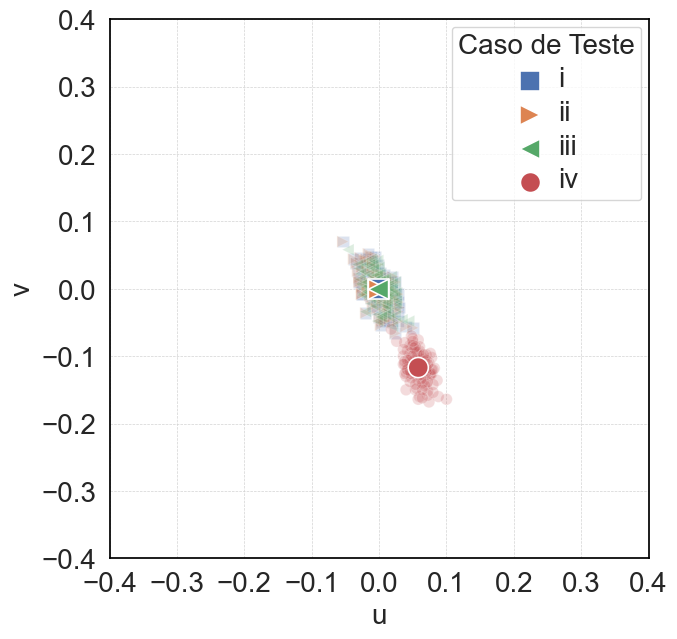

In [8]:
##########################################################
# ESPECIFICAÇÃO PERFEITA: CASOS DE TESTE i, ii, iii e iv #
##########################################################

VisualizationUtilities.plot_test_cases_contours(
    parser=parser,
    test_cases=['i','ii','iii','iv'],
    equal_aspect=True,
    u_range=(-0.4, 0.4),
    v_range=(-0.4, 0.4),
    marker_size=70,
    save_dir=posterior_contour_dir,
    save_name='maximos_curvas_nivel_i_iv'
)

,test_case,u_mean,v_mean,u_std,v_std
0,v,0.043240,-0.135967,0.016620,0.025969
1,vi,0.043240,-0.135967,0.016620,0.025969
2,vii,0.033107,-0.115736,0.015082,0.022042
3,viii,0.090727,-0.236182,0.013493,0.023004


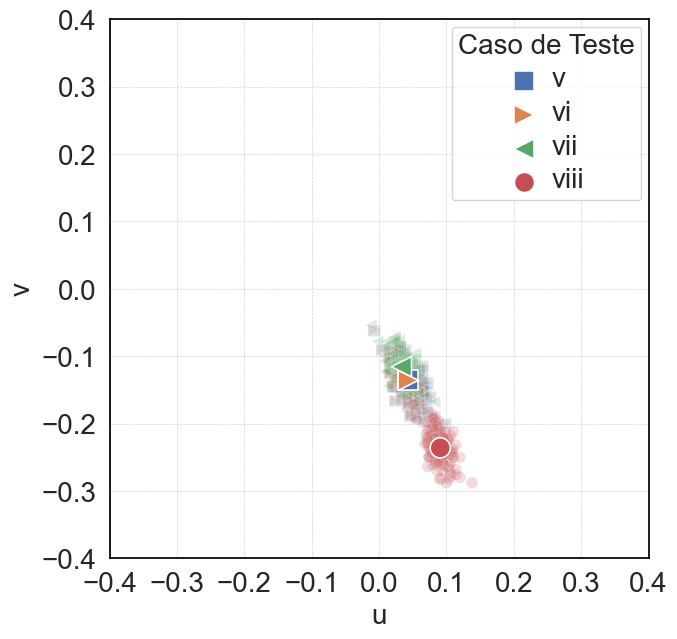

In [9]:
#################################################################
# ESPECIFICAÇÃO MUITO INCORRETA: CASOS DE TESTE ix, x, xi e xii #
#################################################################

VisualizationUtilities.plot_test_cases_contours(
    parser=parser,
    test_cases=['v','vi','vii','viii'],
    equal_aspect=True,
    marker_size=70,
    u_range=(-0.4, 0.4),
    v_range=(-0.4, 0.4),
    save_dir=posterior_contour_dir,
    save_name='maximos_curvas_nivel_v_viii'
)

,test_case,u_mean,v_mean,u_std,v_std
0,ix,-0.457917,1.364678,0.035672,0.034566
1,x,-0.457868,1.364628,0.035641,0.034575
2,xi,-0.208149,0.969091,0.018190,0.017637
3,xii,-0.099901,0.781686,0.015329,0.015697


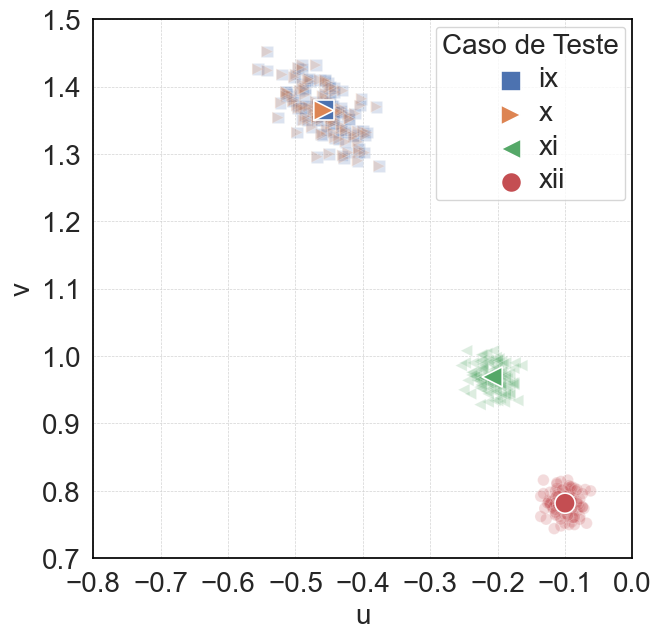

In [10]:
#################################################################
# ESPECIFICAÇÃO MUITO INCORRETA: CASOS DE TESTE ix, x, xi e xii #
#################################################################

VisualizationUtilities.plot_test_cases_contours(
    parser=parser,
    test_cases=['ix','x','xi','xii'],
    equal_aspect=True,
    marker_size=70,
    u_range=(-0.8, 0.0),
    v_range=(0.7, 1.5),
    save_dir=posterior_contour_dir,
    save_name='maximos_curvas_nivel_ix_xii',
    legend_location='upper right'
)

## 2.2. Estimation and Source Recovery Errors

,estimate_type,test_case,error_mean,error_std
0,posteriori_grid,i,0.023230,0.015525
1,posteriori_grid,ii,0.023230,0.015525
2,posteriori_grid,iii,0.020299,0.012965
3,posteriori_grid,iv,0.117274,0.020308
4,posteriori_grid,ix,1.287735,0.036520
5,posteriori_grid,v,0.128134,0.025026
6,posteriori_grid,vi,0.128134,0.025026
7,posteriori_grid,vii,0.108257,0.021040
8,posteriori_grid,viii,0.226513,0.021693
9,posteriori_grid,x,1.287679,0.036517


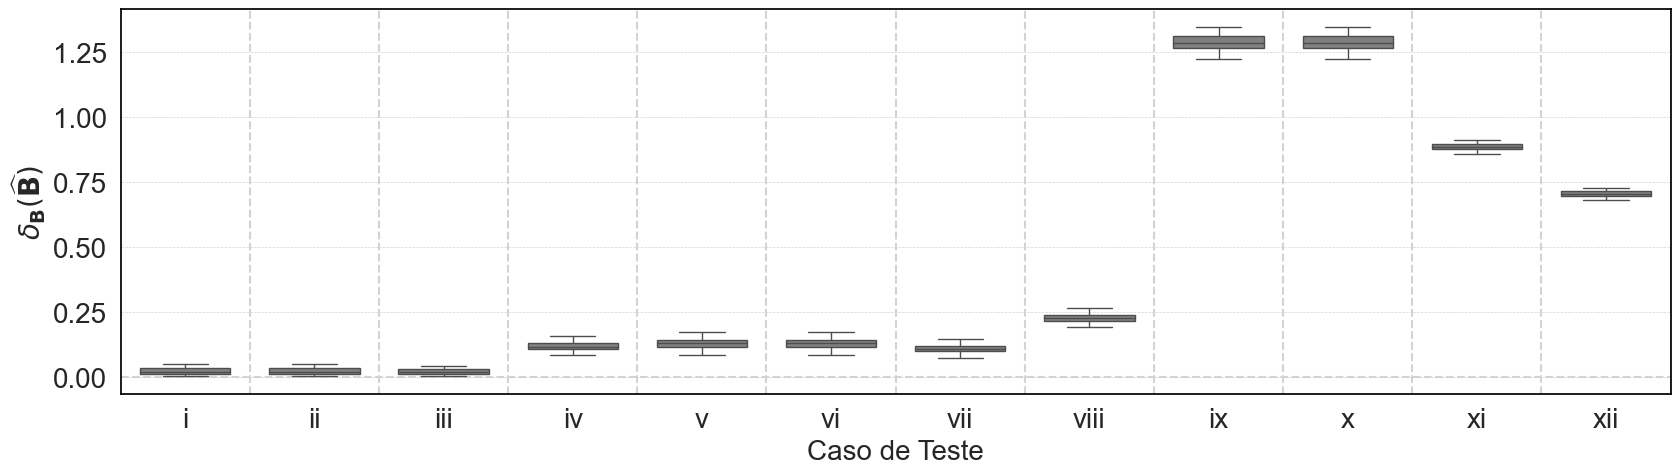

In [11]:
VisualizationUtilities.plot_recovery_errors(
    parser=parser,
    error_type='B_errors',
    estimate_type='posteriori_grid',
    whis_lims=(5,95),
    box_color='gray',
    save_dir=posterior_contour_dir,
    label_size=20,
    legend_size=20
)

,estimate_type,test_case,error_mean,error_std
0,posteriori_grid,i,0.024497,0.014581
1,posteriori_grid,ii,0.024497,0.014581
2,posteriori_grid,iii,0.022009,0.012745
3,posteriori_grid,iv,0.106634,0.020314
4,posteriori_grid,ix,1.285079,0.030454
5,posteriori_grid,v,0.129945,0.024302
6,posteriori_grid,vi,0.129945,0.024302
7,posteriori_grid,vii,0.112246,0.021041
8,posteriori_grid,viii,0.219296,0.022234
9,posteriori_grid,x,1.285044,0.030469


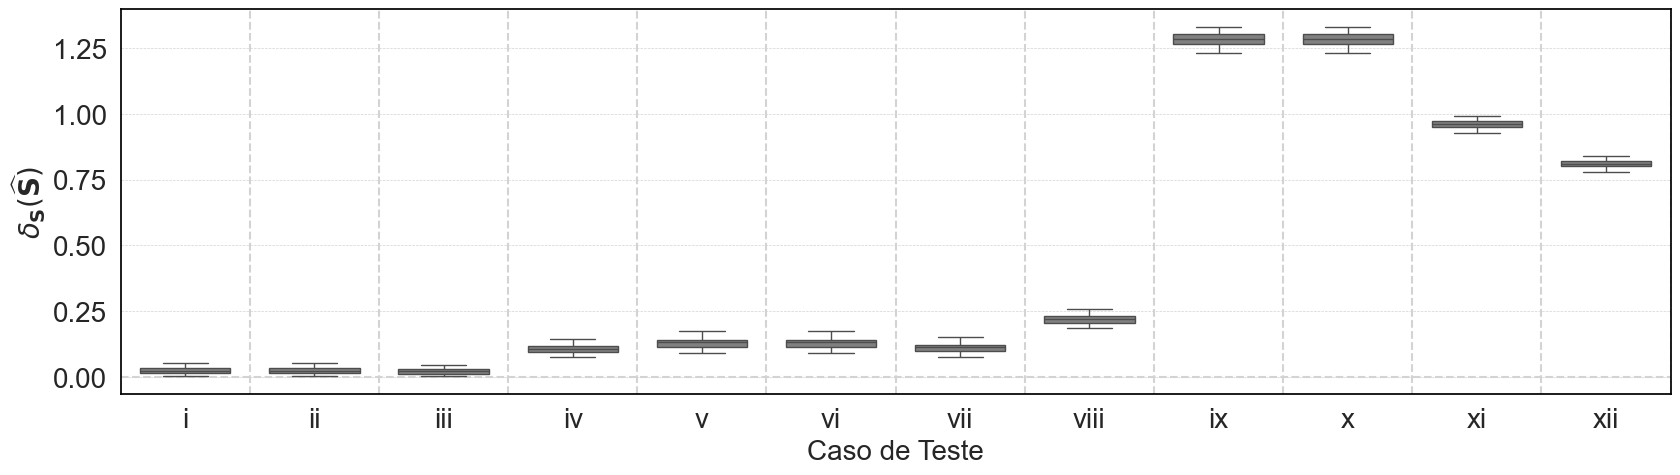

In [12]:
VisualizationUtilities.plot_recovery_errors(
    parser=parser,
    error_type='s_errors',
    estimate_type='posteriori_grid',
    whis_lims=(5,95),
    box_color='gray',
    save_dir=posterior_contour_dir,
    label_size=20,
    legend_size=20
)

In [13]:
AnalysisUtilities.compare_average_B(parser=parser)

Projection onto B* + uS + vK  (Frobenius inner product, S ⟂ K):
  ΔB = B̂ − B*
  u  = ⟨ΔB,S⟩/‖S‖² = (Δ12+Δ21)/2
  v  = ⟨ΔB,K⟩/‖K‖² = (-Δ12+Δ21)/2
  d  = ‖ΔB − uS − vK‖_F   (part of B̂ outside the plane)

=== Test case i ===
B*                           Grid (n=121)                 MAP (n=121)                  MMSE (n=121)                 
[   0.500   -1.000 ]         [   0.500   -1.000 ]         [   0.497   -1.003 ]         [   0.493   -1.006 ]         
[   0.500    1.000 ]         [   0.498    1.000 ]         [   0.499    0.993 ]         [   0.501    0.986 ]         
                             ΔB=[   0.000   -0.000 ]      ΔB=[  -0.003   -0.003 ]      ΔB=[  -0.007   -0.006 ]      
                                [  -0.002    0.000 ]         [  -0.001   -0.007 ]         [   0.001   -0.014 ]      
                             u=(-0.000 -0.002)/2=-0.001   u=(-0.003 -0.001)/2=-0.002   u=(-0.006 +0.001)/2=-0.003   
                             v=(+0.000 -0.002)/2=-0.001   v=(+0.003 -0.001

(                    b11    b12    b21    b22      u      v  u_std  v_std  \
 test_case method                                                           
 i         Grid    0.500 -1.000  0.498  1.000 -0.001 -0.001  0.017  0.026   
           MAP     0.497 -1.003  0.499  0.993 -0.002  0.001  0.026  0.062   
           MMSE    0.493 -1.006  0.501  0.986 -0.003  0.003  0.026  0.062   
 ii        Grid    0.500 -1.000  0.498  1.000 -0.001 -0.001  0.017  0.026   
           MAP     0.496 -1.003  0.499  0.992 -0.002  0.001  0.026  0.062   
           MMSE    0.493 -1.006  0.501  0.985 -0.003  0.003  0.027  0.062   
 iii       Grid    0.500 -1.000  0.498  1.000 -0.001 -0.001  0.015  0.022   
           MAP     0.499 -1.002  0.499  0.997 -0.002  0.001  0.016  0.029   
           MMSE    0.498 -1.004  0.500  0.995 -0.002  0.002  0.016  0.029   
 iv        Grid    0.500 -0.825  0.441  1.000  0.058 -0.117  0.013  0.022   
           MAP     0.695  0.020 -0.011  1.328  0.255 -0.766  0.060  0.181   

# 2.3. Statistical Analysis

### 2.3.1. Same source: paired t-test

In [14]:
ht_source_model = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    test_pairs=AnalysisUtilities.get_test_case_pairs(method='same_source'),
    analysis='posteriori_grid',
    test_type='paired'
)

In [15]:
# Results for u and v
ht_source_model[
    ht_source_model.metric.isin(['u', 'v'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,ii,u,-0.000942,-0.000942,0.000000,NaN,120.0,NaN,NaN,False
1,i,ii,v,-0.000893,-0.000893,0.000000,NaN,120.0,NaN,NaN,False
4,i,iii,u,-0.000942,-0.000909,-0.000033,-0.146053,120.0,8.841247e-01,1.000000e+00,False
5,i,iii,v,-0.000893,-0.000876,-0.000017,-0.044404,120.0,9.646566e-01,1.000000e+00,False
8,i,iv,u,-0.000942,0.058116,-0.059058,-135.640627,120.0,3.610180e-133,3.249162e-132,True
9,i,iv,v,-0.000893,-0.116959,0.116066,223.395812,120.0,4.584034e-159,4.125630e-158,True
12,ii,iii,u,-0.000942,-0.000909,-0.000033,-0.146053,120.0,8.841247e-01,1.000000e+00,False
13,ii,iii,v,-0.000893,-0.000876,-0.000017,-0.044404,120.0,9.646566e-01,1.000000e+00,False
16,ii,iv,u,-0.000942,0.058116,-0.059058,-135.640627,120.0,3.610180e-133,3.249162e-132,True
17,ii,iv,v,-0.000893,-0.116959,0.116066,223.395812,120.0,4.584034e-159,4.125630e-158,True


In [16]:
# Results for delta_S
ht_source_model[
    ht_source_model.metric.isin(['delta_B','delta_S'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
2,i,ii,delta_B,0.023230,0.023230,0.000000,NaN,120.0,NaN,NaN,False
3,i,ii,delta_S,0.024497,0.024497,0.000000,NaN,120.0,NaN,NaN,False
6,i,iii,delta_B,0.023230,0.020299,0.002931,11.362256,120.0,9.317064e-21,2.795119e-20,True
7,i,iii,delta_S,0.024497,0.022009,0.002488,11.305737,120.0,1.272500e-20,3.817501e-20,True
10,i,iv,delta_B,0.023230,0.117274,-0.094044,-41.734737,120.0,2.696026e-73,1.348013e-72,True
11,i,iv,delta_S,0.024497,0.106634,-0.082138,-39.333329,120.0,2.043608e-70,1.021804e-69,True
14,ii,iii,delta_B,0.023230,0.020299,0.002931,11.362256,120.0,9.317064e-21,2.795119e-20,True
15,ii,iii,delta_S,0.024497,0.022009,0.002488,11.305737,120.0,1.272500e-20,3.817501e-20,True
18,ii,iv,delta_B,0.023230,0.117274,-0.094044,-41.734737,120.0,2.696026e-73,1.348013e-72,True
19,ii,iv,delta_S,0.024497,0.106634,-0.082138,-39.333329,120.0,2.043608e-70,1.021804e-69,True


### 2.3.2. Same prior: independent t-test

In [17]:
ht_prior = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    test_pairs=AnalysisUtilities.get_test_case_pairs(method='same_prior'),
    analysis='posteriori_grid',
    test_type='independent'
)

In [18]:
# Results for u and v
ht_prior[
    ht_prior.metric.isin(['u', 'v'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,v,u,-0.000942,0.043240,-0.044182,-20.178509,240.0,1.299922e-53,5.199687e-53,True
1,i,v,v,-0.000893,-0.135967,0.135074,40.434921,240.0,4.041415e-109,1.141470e-108,True
4,i,ix,u,-0.000942,-0.457917,0.456975,126.606781,240.0,9.456727e-222,8.511055e-221,True
5,i,ix,v,-0.000893,1.364678,-1.365570,-347.299874,240.0,0.000000e+00,0.000000e+00,True
8,v,ix,u,0.043240,-0.457917,0.501157,140.081708,240.0,3.752058e-232,4.127264e-231,True
9,v,ix,v,-0.135967,1.364678,-1.500645,-381.802262,240.0,0.000000e+00,0.000000e+00,True
12,ii,vi,u,-0.000942,0.043240,-0.044182,-20.178509,240.0,1.299922e-53,5.199687e-53,True
13,ii,vi,v,-0.000893,-0.135967,0.135074,40.434921,240.0,4.041415e-109,1.141470e-108,True
16,ii,x,u,-0.000942,-0.457868,0.456926,126.680564,240.0,8.239622e-222,8.239622e-221,True
17,ii,x,v,-0.000893,1.364628,-1.365521,-347.234803,240.0,0.000000e+00,0.000000e+00,True


In [19]:
# Results for delta_S
ht_prior[
    ht_prior.metric.isin(['delta_B','delta_S'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
2,i,v,delta_B,0.023230,0.128134,-0.104905,-39.182289,240.0,2.862832e-106,8.588495e-106,True
3,i,v,delta_S,0.024497,0.129945,-0.105448,-40.928032,240.0,3.180317e-110,9.540951e-110,True
6,i,ix,delta_B,0.023230,1.287735,-1.264505,-350.520527,240.0,0.000000e+00,0.000000e+00,True
7,i,ix,delta_S,0.024497,1.285079,-1.260583,-410.679462,240.0,0.000000e+00,0.000000e+00,True
10,v,ix,delta_B,0.128134,1.287735,-1.159601,-288.119888,240.0,7.750363e-307,6.200290e-306,True
11,v,ix,delta_S,0.129945,1.285079,-1.155134,-326.127619,240.0,1.015601e-319,8.124811e-319,True
14,ii,vi,delta_B,0.023230,0.128134,-0.104905,-39.182289,240.0,2.862832e-106,8.588495e-106,True
15,ii,vi,delta_S,0.024497,0.129945,-0.105448,-40.928032,240.0,3.180317e-110,9.540951e-110,True
18,ii,x,delta_B,0.023230,1.287679,-1.264449,-350.521764,240.0,0.000000e+00,0.000000e+00,True
19,ii,x,delta_S,0.024497,1.285044,-1.260548,-410.495482,240.0,0.000000e+00,0.000000e+00,True


In [20]:
for test_case in parser.parsed_results.keys():
    del parser.parsed_results[test_case]['posteriori_grid']

# 3. MCMC and Gradient Ascent Convergence

## 3.1. MCMC convergence analysis

/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:421: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.boxplot(
/Users/leonardo.tessarolo/git/bayesian_bss/src/visualizations.py:436: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  sns.boxplot(


,test_case,coefficient,r_hat_mean,r_hat_std,r_hat_min,r_hat_max,r_hat_median,ess_mean,ess_std,ess_min,ess_max,ess_median
0,i,b_11,1.003330,0.002257,1.000015,1.009871,1.003058,502.219119,160.022648,202.879798,905.118711,490.860208
1,i,b_12,1.003207,0.002329,1.000030,1.009901,1.002722,510.310889,161.695042,209.646744,914.443204,498.539927
2,i,b_21,1.003187,0.002291,0.999981,1.009971,1.002892,511.970804,162.997410,204.849165,968.543204,503.719942
3,i,b_22,1.003337,0.002395,1.000019,1.009456,1.003115,499.000385,157.038647,203.757269,900.401751,493.726219
4,ii,b_11,1.003189,0.002108,0.999988,1.008247,1.002904,507.687833,166.056078,185.077628,959.044650,479.736355
5,ii,b_12,1.003067,0.002089,0.999998,1.009137,1.002604,518.551780,167.421354,200.710977,987.106782,497.892372
6,ii,b_21,1.003062,0.002141,1.000075,1.008929,1.002498,518.586575,167.475458,200.266775,956.651645,493.602016
7,ii,b_22,1.003270,0.002156,0.999997,1.008280,1.002862,508.178471,164.533678,194.639860,982.240637,485.835327
8,iii,b_11,1.001170,0.001013,0.999943,1.006458,1.000960,1138.112648,202.659336,687.754534,1662.484073,1123.160443
9,iii,b_12,1.001111,0.001022,1.000003,1.006282,1.000770,1179.378619,208.619251,739.882699,1644.031687,1171.421177


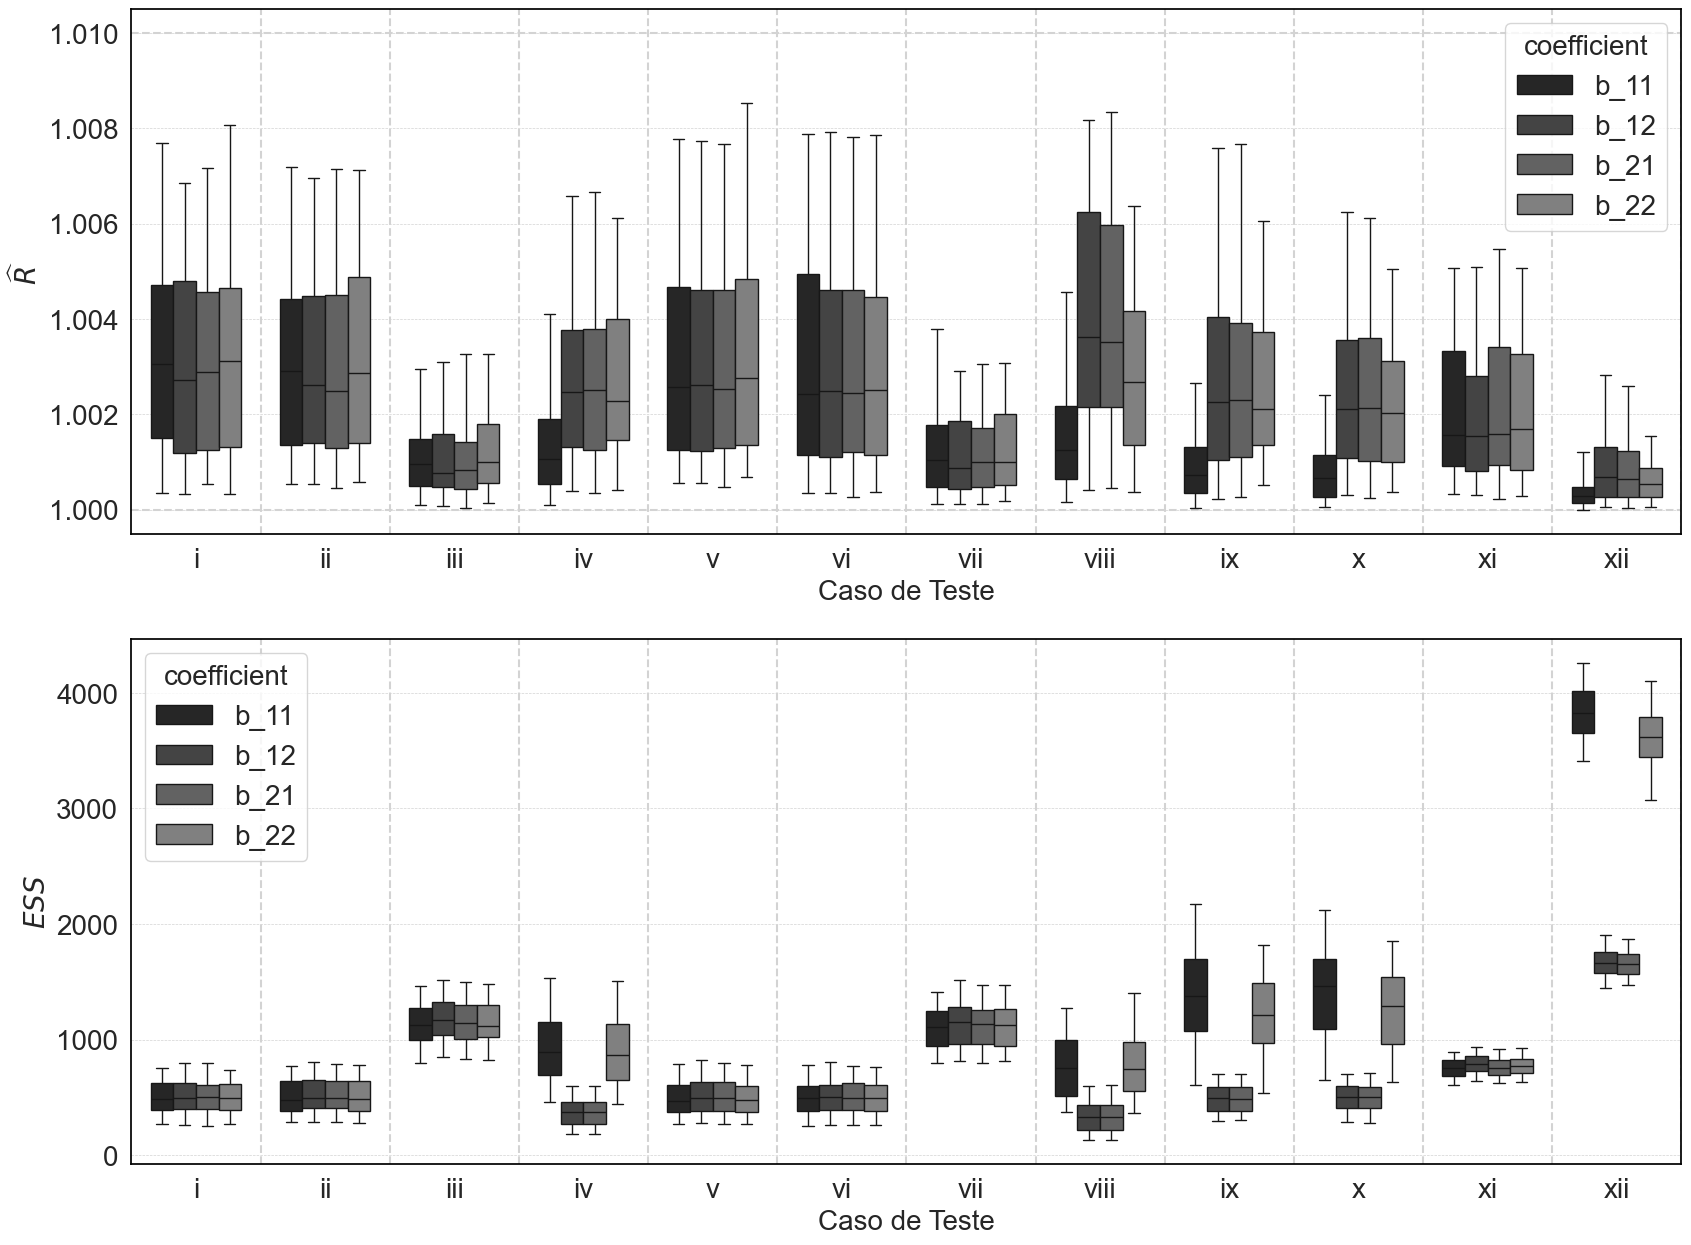

In [21]:
VisualizationUtilities.mcmc_diagnostics_analysis(
    parser=parser,
    return_stats=True,
    save_dir=mmse_dir
)

In [22]:
# VisualizationUtilities.mcmc_trace_plots(
#     parser=parser,
#     B_true=parser.execution_config['general']['B'],
#     save_dir=mmse_dir
# )

## 3.2. Gradient Ascent Convergence analysis

## 3.2.1. Evolution of log-posteriors

In [23]:
# VisualizationUtilities.gradient_ascent_posteriori_evolutions(
#     parser=parser,
#     save_dir=map_dir
# )

## 3.2.2. Evolution of coefficients

In [24]:
# VisualizationUtilities.grad_asc_trace_plots(
#     parser=parser,
#     B_true=parser.execution_config['general']['B'],
#     save_dir=map_dir
# )

# 4. MAP and MMSE Performance

## 4.1. MAP

In [25]:
pprint.pp(
    {
        c: np.mean(
            results['map']['B_estimates'],
            axis=0
        ) for c, results in parser.parsed_results.items()
    }
)

{'i': array([[ 0.49650288, -1.00294888],
       [ 0.49919398,  0.99252901]]),
 'ii': array([[ 0.49644085, -1.00308279],
       [ 0.49925555,  0.99239487]]),
 'iii': array([[ 0.49865432, -1.00247093],
       [ 0.49927613,  0.9972763 ]]),
 'iv': array([[ 0.69455102,  0.02010031],
       [-0.01103815,  1.32829595]]),
 'v': array([[ 0.45057785, -0.91117201],
       [ 0.45216474,  0.90262906]]),
 'vi': array([[ 0.45052235, -0.91129452],
       [ 0.45222078,  0.90250874]]),
 'vii': array([[ 0.45419242, -0.91978652],
       [ 0.45431318,  0.91499805]]),
 'viii': array([[ 0.62705822,  0.02039344],
       [-0.01114502,  1.2153723 ]]),
 'ix': array([[ 1.49273101,  0.01107713],
       [-0.00791131,  2.99091399]]),
 'x': array([[ 1.49275434,  0.01343719],
       [-0.00904597,  2.990862  ]]),
 'xi': array([[ 0.96685324, -1.74619599],
       [ 0.9665951 ,  1.74126877]]),
 'xii': array([[ 1.43215561e+00,  4.78089052e-04],
       [-2.25824344e-03,  2.34101485e+00]])}


,estimate_type,test_case,error_mean,error_std
0,map,i,0.070609,0.042603
1,map,ii,0.070664,0.042524
2,map,iii,0.036748,0.017358
3,map,iv,0.763172,0.163097
4,map,ix,1.585292,0.081844
5,map,v,0.116581,0.032053
6,map,vi,0.116578,0.032045
7,map,vii,0.091586,0.016979
8,map,viii,0.740380,0.181719
9,map,x,1.585955,0.081457


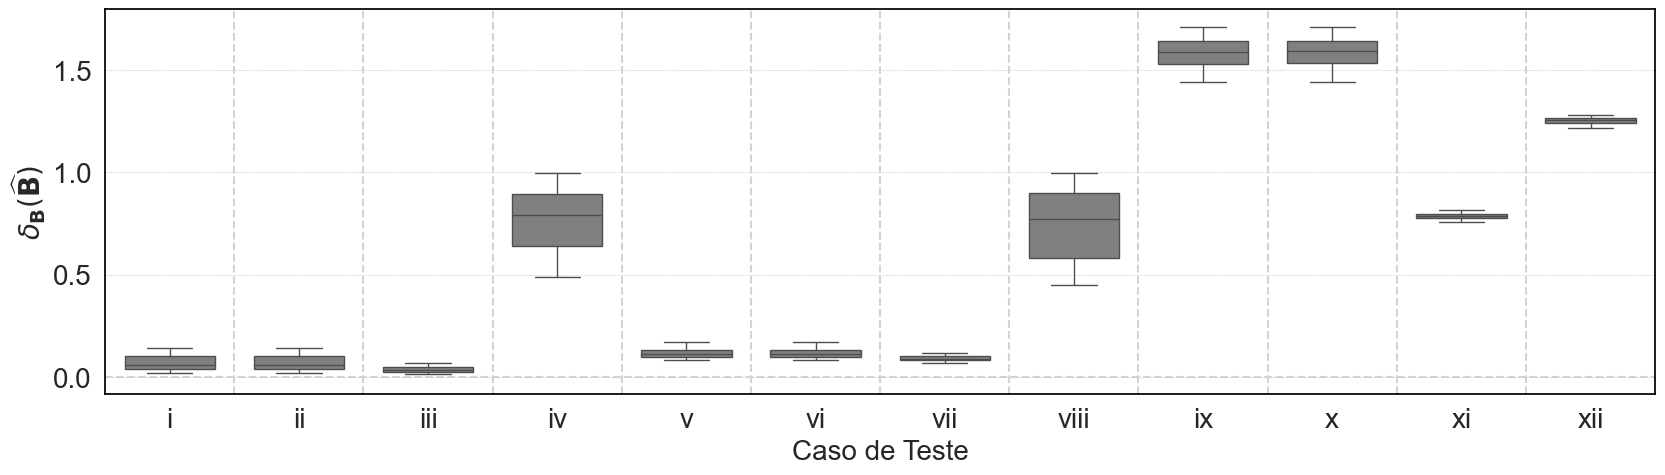

In [26]:
VisualizationUtilities.plot_recovery_errors(
    parser=parser,
    error_type='B_errors',
    estimate_type='map',
    save_dir=map_dir
)

,estimate_type,test_case,error_mean,error_std
0,map,i,0.072642,0.041561
1,map,ii,0.072685,0.041494
2,map,iii,0.040456,0.018234
3,map,iv,0.768006,0.162896
4,map,ix,1.583168,0.074859
5,map,v,0.119548,0.030416
6,map,vi,0.119543,0.030411
7,map,vii,0.096545,0.015996
8,map,viii,0.742777,0.182023
9,map,x,1.583840,0.074454


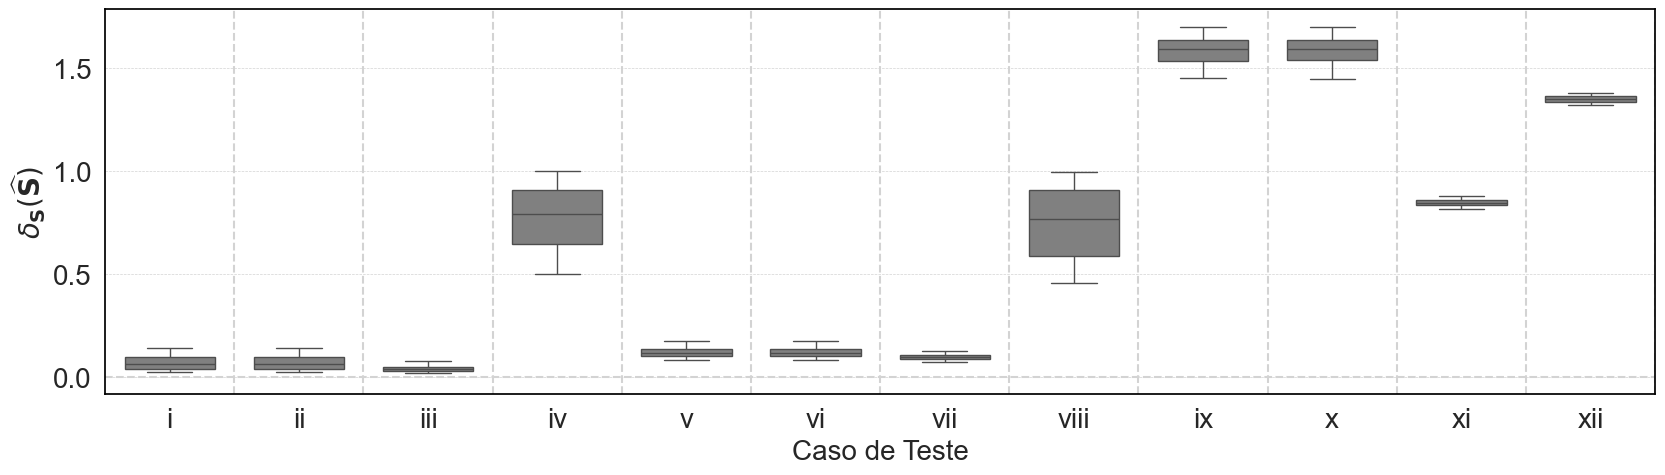

In [27]:
VisualizationUtilities.plot_recovery_errors(
    parser=parser,
    error_type='s_errors',
    estimate_type='map',
    save_dir=map_dir
)

## 4.2. MMSE

In [28]:
pprint.pp(
    {
        c: np.mean(
            results['mmse']['B_estimates'],
            axis=0
        ) for c, results in parser.parsed_results.items()
    }
)

{'i': array([[ 0.49323309, -1.00564003],
       [ 0.50059128,  0.98568526]]),
 'ii': array([[ 0.49309476, -1.00578767],
       [ 0.5006311 ,  0.98535479]]),
 'iii': array([[ 0.49780828, -1.00387894],
       [ 0.50008272,  0.99531906]]),
 'iv': array([[ 0.69450563,  0.00595991],
       [-0.00368738,  1.32712717]]),
 'v': array([[ 0.44771233, -0.91333376],
       [ 0.4532908 ,  0.89656696]]),
 'vi': array([[ 0.44762604, -0.91355123],
       [ 0.45339332,  0.89642496]]),
 'vii': array([[ 0.45327526, -0.92135679],
       [ 0.45520778,  0.91293385]]),
 'viii': array([[ 0.62731482,  0.00662894],
       [-0.00410059,  1.21490073]]),
 'ix': array([[ 1.48918958e+00, -5.90034749e-03],
       [ 6.18947837e-04,  2.98133994e+00]]),
 'x': array([[ 1.48924492e+00, -7.91298724e-03],
       [ 1.58145957e-03,  2.98137860e+00]]),
 'xi': array([[ 0.96385469, -1.74913933],
       [ 0.96888142,  1.73566066]]),
 'xii': array([[ 1.43212356e+00, -4.35506378e-03],
       [ 6.67216242e-04,  2.34027364e+00]])}


,estimate_type,test_case,error_mean,error_std
0,mmse,i,0.072131,0.042631
1,mmse,ii,0.072158,0.043278
2,mmse,iii,0.037012,0.017147
3,mmse,iv,0.752974,0.144904
4,mmse,ix,1.574483,0.083498
5,mmse,v,0.118860,0.031691
6,mmse,vi,0.118634,0.031770
7,mmse,vii,0.091801,0.016780
8,mmse,viii,0.730530,0.162127
9,mmse,x,1.573808,0.082855


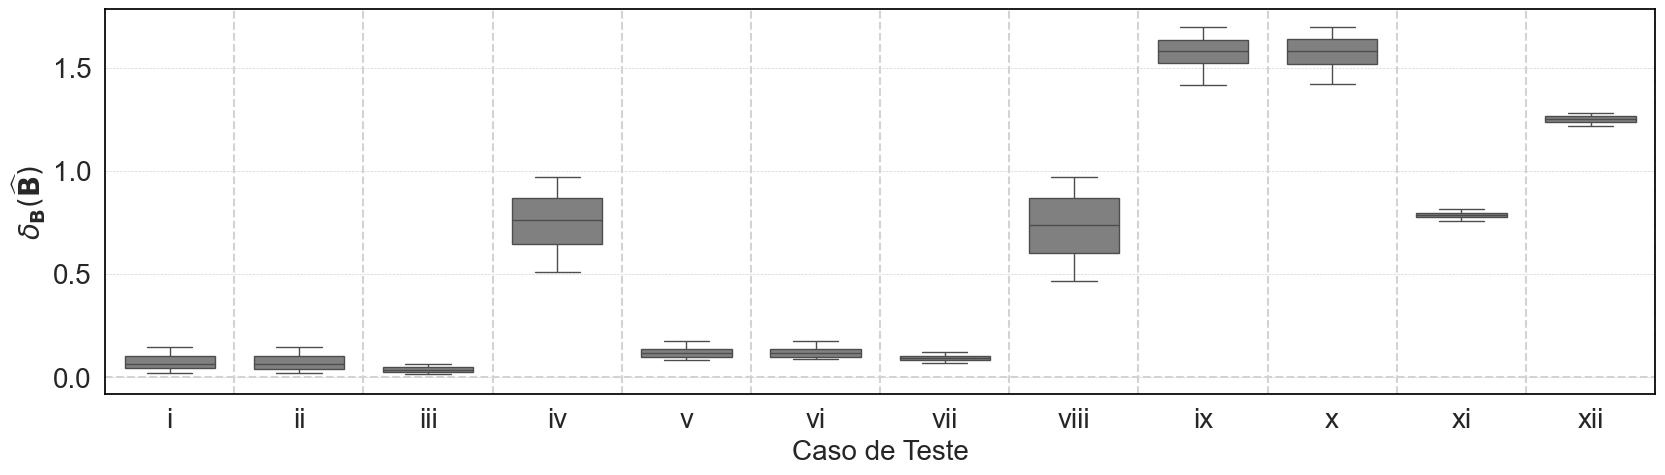

In [29]:
VisualizationUtilities.plot_recovery_errors(
    parser=parser,
    error_type='B_errors',
    estimate_type='mmse',
    save_dir=mmse_dir
)

,estimate_type,test_case,error_mean,error_std
0,mmse,i,0.074194,0.041337
1,mmse,ii,0.074099,0.042097
2,mmse,iii,0.040718,0.018047
3,mmse,iv,0.757750,0.144465
4,mmse,ix,1.572795,0.076360
5,mmse,v,0.121691,0.030070
6,mmse,vi,0.121458,0.030006
7,mmse,vii,0.096685,0.015838
8,mmse,viii,0.732884,0.162076
9,mmse,x,1.572153,0.075857


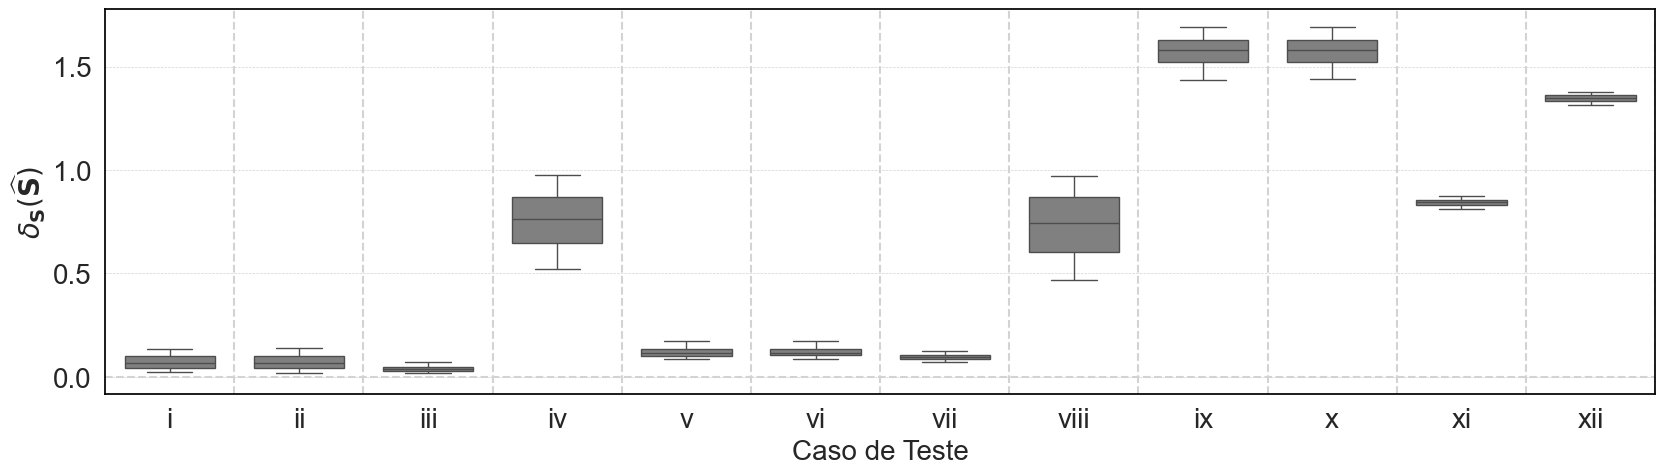

In [30]:
VisualizationUtilities.plot_recovery_errors(
    parser=parser,
    error_type='s_errors',
    estimate_type='mmse',
    save_dir=mmse_dir
)

# 4.3. MAP vs MMSE

,estimate_type,test_case,error_mean,error_std
0,MAP,i,0.070609,0.042603
1,MAP,ii,0.070664,0.042524
2,MAP,iii,0.036748,0.017358
3,MAP,iv,0.763172,0.163097
4,MAP,ix,1.585292,0.081844
5,MAP,v,0.116581,0.032053
6,MAP,vi,0.116578,0.032045
7,MAP,vii,0.091586,0.016979
8,MAP,viii,0.740380,0.181719
9,MAP,x,1.585955,0.081457


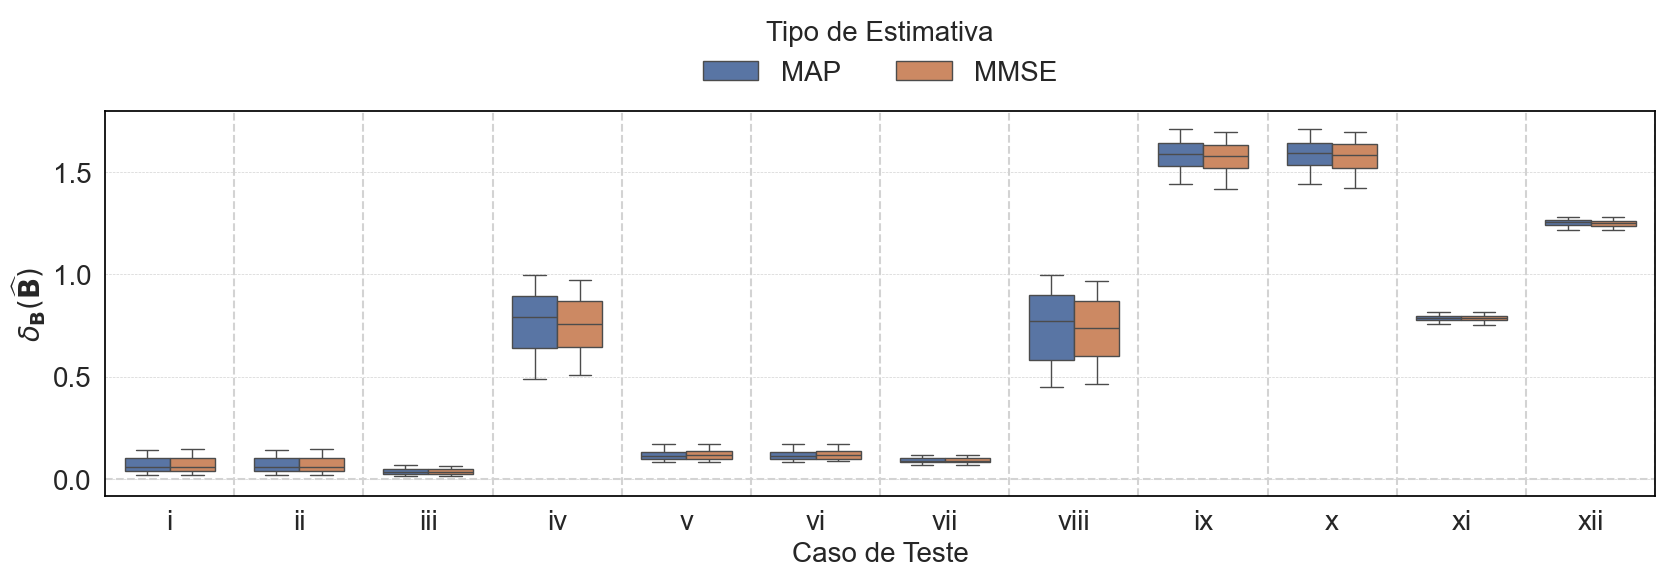

In [44]:
VisualizationUtilities.plot_recovery_errors_map_mmse(
    parser=parser,
    error_type='B_errors',
    save_dir=experiment_dir
)

,estimate_type,test_case,error_mean,error_std
0,MAP,i,0.072642,0.041561
1,MAP,ii,0.072685,0.041494
2,MAP,iii,0.040456,0.018234
3,MAP,iv,0.768006,0.162896
4,MAP,ix,1.583168,0.074859
5,MAP,v,0.119548,0.030416
6,MAP,vi,0.119543,0.030411
7,MAP,vii,0.096545,0.015996
8,MAP,viii,0.742777,0.182023
9,MAP,x,1.583840,0.074454


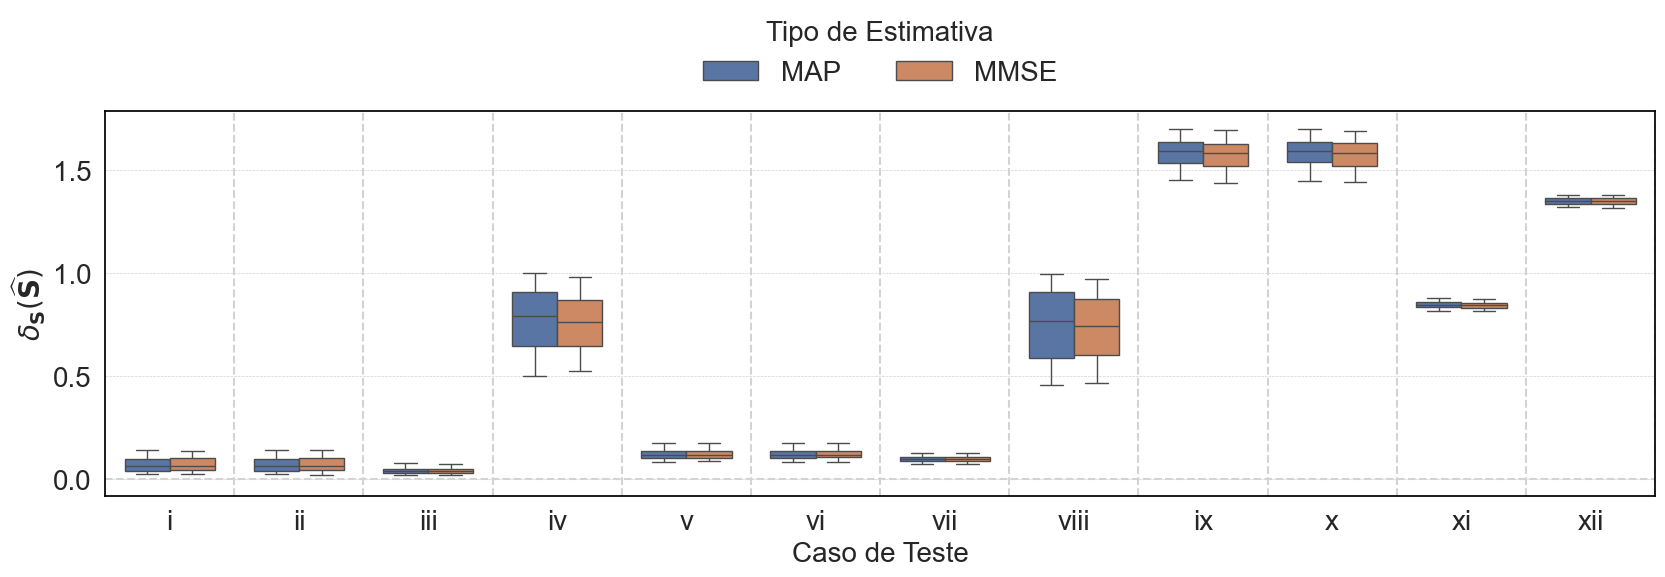

In [45]:
VisualizationUtilities.plot_recovery_errors_map_mmse(
    parser=parser,
    error_type='s_errors',
    save_dir=experiment_dir
)

## 4.3. Análise estatística - MAP

### 4.3.1. Same source: paired t-test

In [31]:
ht_source_model = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    test_pairs=AnalysisUtilities.get_test_case_pairs(method='same_source'),
    analysis='map',
    test_type='paired'
)

In [32]:
# Results for delta_S
ht_source_model[
    ht_source_model.metric.isin(['delta_B','delta_S'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,ii,delta_B,0.070609,0.070664,-0.000056,-2.170098,120.0,3.196966e-02,6.393933e-02,False
1,i,ii,delta_S,0.072642,0.072685,-0.000043,-1.737475,120.0,8.486905e-02,1.697381e-01,False
2,i,iii,delta_B,0.070609,0.036748,0.033861,13.042450,120.0,9.384359e-25,5.630616e-24,True
3,i,iii,delta_S,0.072642,0.040456,0.032186,12.773734,120.0,4.043591e-24,2.426154e-23,True
4,i,iv,delta_B,0.070609,0.763172,-0.692564,-44.657336,120.0,1.303384e-76,1.545466e-75,True
5,i,iv,delta_S,0.072642,0.768006,-0.695364,-44.666401,120.0,1.273766e-76,1.763590e-75,True
6,ii,iii,delta_B,0.070664,0.036748,0.033917,13.096035,120.0,7.017534e-25,4.912274e-24,True
7,ii,iii,delta_S,0.072685,0.040456,0.032229,12.816198,120.0,3.209002e-24,2.246301e-23,True
8,ii,iv,delta_B,0.070664,0.763172,-0.692508,-44.662053,120.0,1.287888e-76,1.545466e-75,True
9,ii,iv,delta_S,0.072685,0.768006,-0.695321,-44.670779,120.0,1.259707e-76,1.763590e-75,True


### 4.3.2. Same prior: independent t-test

In [33]:
ht_prior = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    test_pairs=AnalysisUtilities.get_test_case_pairs(method='same_prior'),
    analysis='map',
    test_type='independent'
)

In [34]:
# Results for delta_S
ht_prior[
    ht_prior.metric.isin(['delta_B','delta_S'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,v,delta_B,0.070609,0.116581,-0.045972,-9.485165,240.0,2.497956e-18,7.490660e-18,True
1,i,v,delta_S,0.072642,0.119548,-0.046906,-10.018245,240.0,5.811613e-20,1.729831e-19,True
2,i,ix,delta_B,0.070609,1.585292,-1.514684,-180.577231,240.0,2.275212e-258,1.592648e-257,True
3,i,ix,delta_S,0.072642,1.583168,-1.510526,-194.058203,240.0,8.004567e-266,5.603197e-265,True
4,v,ix,delta_B,0.116581,1.585292,-1.468712,-183.805714,240.0,3.335669e-260,3.002102e-259,True
5,v,ix,delta_S,0.119548,1.583168,-1.463620,-199.249088,240.0,1.475034e-268,1.327530e-267,True
6,ii,vi,delta_B,0.070664,0.116578,-0.045914,-9.485226,240.0,2.496887e-18,7.490660e-18,True
7,ii,vi,delta_S,0.072685,0.119543,-0.046858,-10.019348,240.0,5.766103e-20,1.729831e-19,True
8,ii,x,delta_B,0.070664,1.585955,-1.515291,-181.396002,240.0,7.742918e-259,6.194335e-258,True
9,ii,x,delta_S,0.072685,1.583840,-1.511155,-195.020741,240.0,2.459592e-266,1.967674e-265,True


## 4.4. Análise estatística - MMSE

### 4.4.1. Same source: paired t-test

In [35]:
ht_source_model = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    test_pairs=AnalysisUtilities.get_test_case_pairs(method='same_source'),
    analysis='mmse',
    test_type='paired'
)

In [36]:
# Results for delta_S
ht_source_model[
    ht_source_model.metric.isin(['delta_B','delta_S'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,ii,delta_B,0.072131,0.072158,-0.000028,-0.082813,120.0,9.341386e-01,9.341386e-01,False
1,i,ii,delta_S,0.074194,0.074099,0.000094,0.280920,120.0,7.792559e-01,7.792559e-01,False
2,i,iii,delta_B,0.072131,0.037012,0.035119,13.404961,120.0,1.319631e-25,6.598155e-25,True
3,i,iii,delta_S,0.074194,0.040718,0.033475,13.262447,120.0,2.849903e-25,1.709942e-24,True
4,i,iv,delta_B,0.072131,0.752974,-0.680843,-49.934639,120.0,3.884380e-82,4.661256e-81,True
5,i,iv,delta_S,0.074194,0.757750,-0.683557,-50.013127,120.0,3.244836e-82,4.542771e-81,True
6,ii,iii,delta_B,0.072158,0.037012,0.035147,13.077470,120.0,7.760754e-25,3.104301e-24,True
7,ii,iii,delta_S,0.074099,0.040718,0.033381,12.832525,120.0,2.936180e-24,1.174472e-23,True
8,ii,iv,delta_B,0.072158,0.752974,-0.680816,-49.829510,120.0,4.944771e-82,5.439248e-81,True
9,ii,iv,delta_S,0.074099,0.757750,-0.683651,-49.911532,120.0,4.095861e-82,5.324619e-81,True


### 4.4.2. Same prior: independent t-test

In [37]:
ht_prior = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    test_pairs=AnalysisUtilities.get_test_case_pairs(method='same_prior'),
    analysis='mmse',
    test_type='independent'
)

In [38]:
# Results for delta_S
ht_prior[
    ht_prior.metric.isin(['delta_B','delta_S'])
][[
    'case_0',
    'case_1',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case_0,case_1,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,v,delta_B,0.072131,0.118860,-0.046729,-9.676551,240.0,6.538347e-19,1.961504e-18,True
1,i,v,delta_S,0.074194,0.121691,-0.047497,-10.221103,240.0,1.359776e-20,4.079327e-20,True
2,i,ix,delta_B,0.072131,1.574483,-1.502352,-176.273778,240.0,7.117876e-256,4.982513e-255,True
3,i,ix,delta_S,0.074194,1.572795,-1.498602,-189.846928,240.0,1.497687e-263,1.061383e-262,True
4,v,ix,delta_B,0.118860,1.574483,-1.455623,-179.285471,240.0,1.258440e-257,1.132596e-256,True
5,v,ix,delta_S,0.121691,1.572795,-1.451105,-194.500098,240.0,4.653217e-266,4.187895e-265,True
6,ii,vi,delta_B,0.072158,0.118634,-0.046476,-9.522384,240.0,1.926507e-18,3.853014e-18,True
7,ii,vi,delta_S,0.074099,0.121458,-0.047359,-10.077205,240.0,3.814625e-20,7.629250e-20,True
8,ii,x,delta_B,0.072158,1.573808,-1.501650,-176.707710,240.0,3.963085e-256,3.170468e-255,True
9,ii,x,delta_S,0.074099,1.572153,-1.498053,-189.943464,240.0,1.326729e-263,1.061383e-262,True


## 4.4. Análise estatística - MAP vs MMSE

In [39]:
ht_map_mmse = HypothesisTestsCases.run_pairwise_ttests(
    parser=parser,
    analysis='map_vs_mmse'
)

In [40]:
ht_map_mmse[[
    'case',
    'metric',
    'mean_0',
    'mean_1',
    'mean_difference',
    'statistic',
    'degrees_of_freedom',
    'pvalue',
    'pvalue_holm',
    'reject_holm'
]]

,case,metric,mean_0,mean_1,mean_difference,statistic,degrees_of_freedom,pvalue,pvalue_holm,reject_holm
0,i,delta_B,0.070609,0.072131,-0.001522,-3.029058,120.0,3.004387e-03,1.201755e-02,True
1,i,delta_S,0.072642,0.074194,-0.001552,-3.214897,120.0,1.676728e-03,6.706913e-03,True
2,ii,delta_B,0.070664,0.072158,-0.001494,-2.704924,120.0,7.826070e-03,2.347821e-02,True
3,ii,delta_S,0.072685,0.074099,-0.001414,-2.643273,120.0,9.306968e-03,2.792090e-02,True
4,iii,delta_B,0.036748,0.037012,-0.000264,-1.913074,120.0,5.812124e-02,5.812124e-02,False
5,iii,delta_S,0.040456,0.040718,-0.000262,-1.904596,120.0,5.922638e-02,1.184528e-01,False
6,iv,delta_B,0.763172,0.752974,0.010198,4.559063,120.0,1.246663e-05,7.479976e-05,True
7,iv,delta_S,0.768006,0.757750,0.010256,4.538329,120.0,1.355872e-05,8.135229e-05,True
8,v,delta_B,0.116581,0.118860,-0.002279,-7.971796,120.0,1.025558e-12,8.204463e-12,True
9,v,delta_S,0.119548,0.121691,-0.002143,-7.658034,120.0,5.341566e-12,4.273253e-11,True


# 5. Posterior Properties

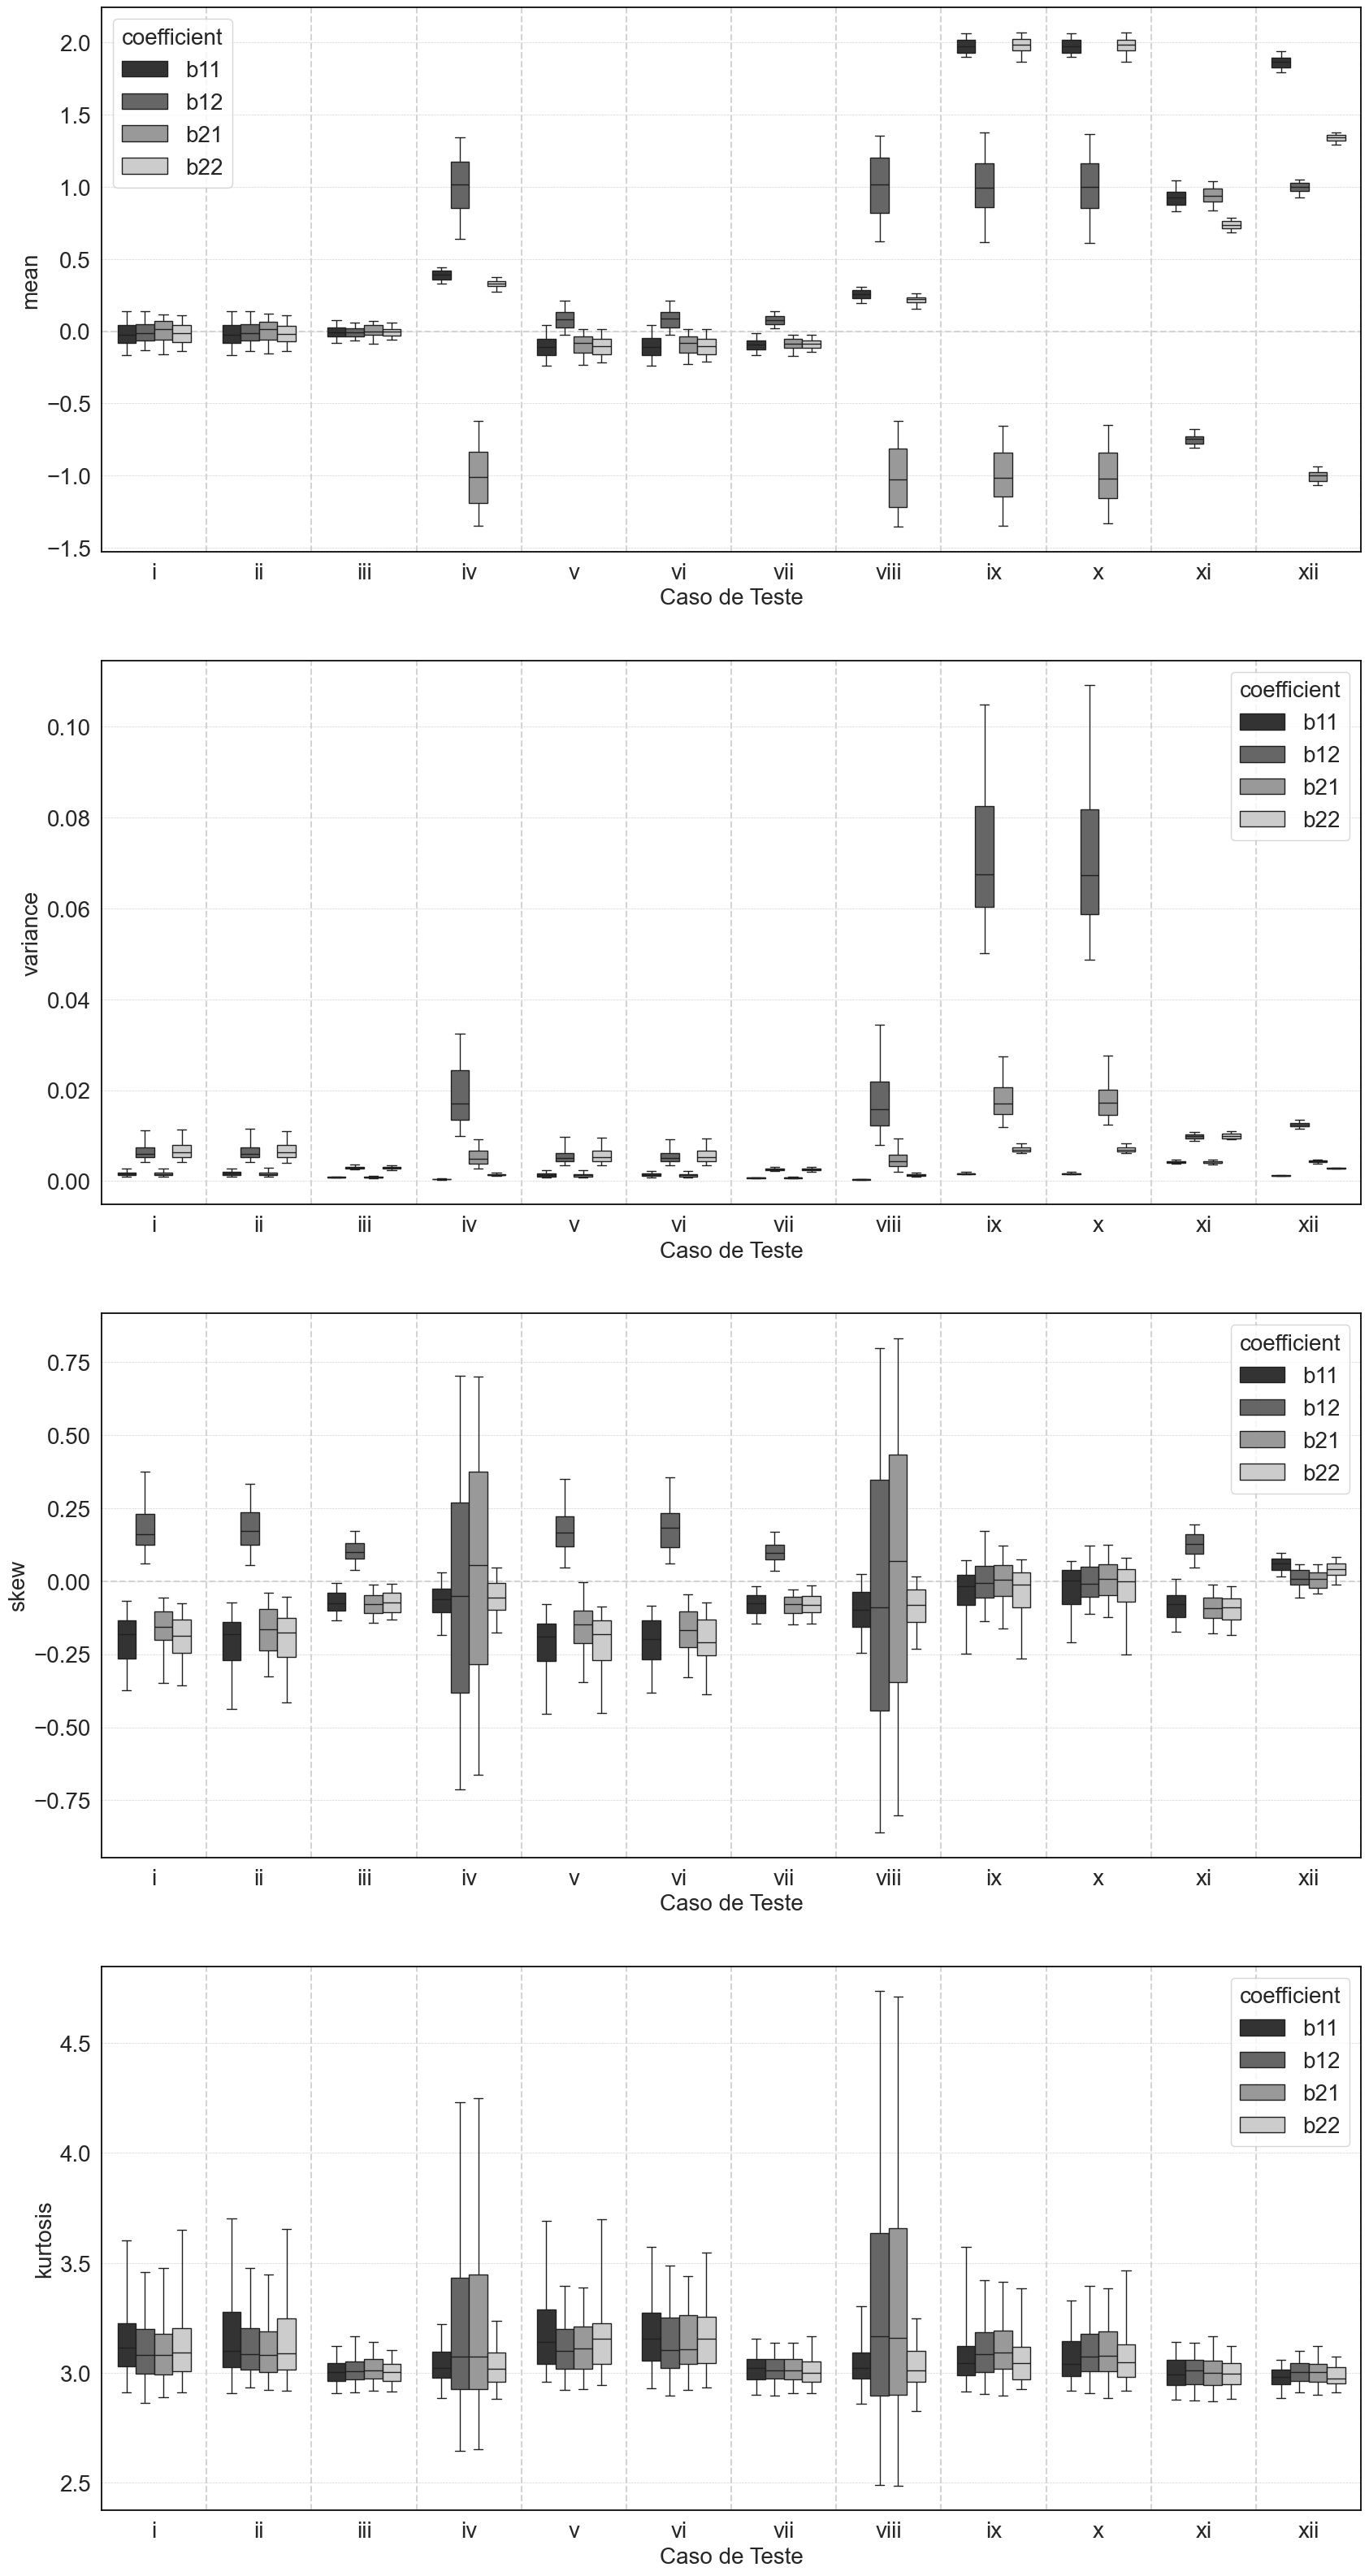

In [41]:
properties_df = VisualizationUtilities.posterior_properties_analysis(
    parser=parser,
    true_B=parser.execution_config['general']['B'],
    save_dir=posterior_properties_dir
)